In [24]:
from langgraph.graph import StateGraph,START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict,Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver

In [2]:
class ChatState(TypedDict):
    # Base message include all types of messages - human message, AI message etc. These are inherted from BaseMessage
    # add_messages work same as operator.add but this is more optimised while appending messages in the list.
    messages : Annotated[list[BaseMessage],add_messages]

In [20]:
llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

In [21]:
def chat_node(state:ChatState):
    # take user query form the state
    messages = state['messages']

    # send to llm 
    response = llm.invoke(messages)

    # response store state
    return {'messages':[response]}

In [25]:
checkpointer = MemorySaver()

graph = StateGraph(ChatState)

graph.add_node('chat_node',chat_node)

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot = graph.compile(checkpointer=checkpointer)

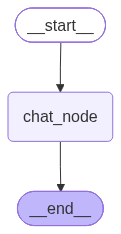

In [7]:
chatbot

In [8]:
initial_state = {
    'messages' : [HumanMessage(content= 'What is the capital of India')]
}

chatbot.invoke(initial_state)

{'messages': [HumanMessage(content='What is the capital of India', additional_kwargs={}, response_metadata={}, id='62fd1487-f645-412d-9307-235ed02d6756'),
  AIMessage(content=[{'type': 'text', 'text': 'The capital of India is **New Delhi**.', 'extras': {'signature': 'EswDCskDAWkUfRPBENndW2zoFz47XdqOtzB8u//DqTRJhVLpbsZ20vDGfjWO2B7iK04TvN2Bxmgtno1CzNc5+LWOu2ub2xBCfdf/F7hKylEYysIFtQrdCqhCipgEO0fVCByvuZROyLyx8MjJckG6VJow8f7ZZ0dIE7tqTPCfN/fK1bNTXGy2xcNe/07WeAPfaIDZQmNQWZyiiys4Rf2PcExNmN2ke3Mcn1g8z7zCOQCr94UOMzH1WZ71WC5lGbkUG5lBPxTLNe5t6t9VtMaHysWyQeW1HCLBxxXxFxQ0cA5AYO4PuXm8VAbPfLyzn2vvIGgnmyP/Aq+6PD4PpMxXHw9FqeVug0qXKUhQtB9k8XTnNEgcZ9aG5/7NfPTkX24UCBO+7t7nAvVv6QQ/NBXgoB7oj55gwIJpLuGlQnWMBQRxhwZCrCa1Jv/dCkKZArcxdXFCnZOnRKkIRde5niBQll28hcFjZb732nWcdFloIfBcd7Y/nJamTVyUip3fgYZhphykGNHgdfo7inhc4Bv0AIeMqPHAWH5Z2/ikar5IK9+ZwH8Qt35bG4N5hMxoJqoUrDD+JLplOJiaRc4v128nILDD93H2G/mJwX3YYwKuyQ=='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safet

In [28]:
thread_id = '1'

while True:
    user_message = input('Type here : ')

    print('User :', user_message)


    if user_message.strip().lower() in ['exit','quit', 'bye']:
        break


    config = {'configurable': {'thread_id': thread_id}}

    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config= config)

    print('AI:', response['messages'][-1].content)

User : Hi, My name is Yashvi


GoogleModelNotFoundError: Error calling model 'gemini-2.5-flash' (NOT_FOUND): 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}

In [27]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='77b7adbd-7698-41e6-bc87-b3c89b448520')]}, next=('chat_node',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1df78b-e2e7-6997-8000-6b9e7b68c6d2'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-13T15:41:50.498215+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1df78b-e1e1-6930-bfff-7337bf373040'}}, tasks=(PregelTask(id='5aad0724-fd81-f61e-3979-ce6f4a8229a7', name='chat_node', path=('__pregel_pull', 'chat_node'), error='GoogleModelNotFoundError("Error calling model \'gemini-2.5-flash\' (NOT_FOUND): 404 NOT_FOUND. {\'error\': {\'code\': 404, \'message\': \'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions A